In [2]:
# 필요한 라이브러리 설치 및 임포트
import pandas as pd
import datetime

---

# [Step 2] 데이터 전처리

#### **<span style="color:blue">[2-0] air_21, air_22, weather_21, weather_22 데이터 로딩</span>**

In [3]:
# 데이터 로딩
air_21 = pd.read_csv('air_2021.csv', encoding='utf-8', index_col = 0)
air_22 = pd.read_csv('air_2022.csv', encoding='utf-8', index_col = 0)
weather_21 = pd.read_csv('weather_2021.csv', encoding='cp949')
weather_22 = pd.read_csv('weather_2022.csv', encoding='cp949')


In [4]:
air_21.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      8760 non-null   str    
 1   망       8760 non-null   str    
 2   측정소코드   8760 non-null   int64  
 3   측정소명    8760 non-null   str    
 4   측정일시    8760 non-null   int64  
 5   SO2     8648 non-null   float64
 6   CO      8680 non-null   float64
 7   O3      8663 non-null   float64
 8   NO2     8680 non-null   float64
 9   PM10    8655 non-null   float64
 10  PM25    8663 non-null   float64
 11  주소      8760 non-null   str    
dtypes: float64(6), int64(2), str(4)
memory usage: 821.4 KB


#### **<span style="color:blue">[2-1] air_21, air_22 의 '측정일시'를 활용하여 'time' 변수 생성</span>**

* air_21, air_22 의 '측정일시'를 활용하여 'time'변수 생성
* time 변수를 to_datetime으로 데이터 타입 변경
* 참고: 미세먼지 데이터는 1시-24시, 날씨 데이터는 0시-23시로 구성되어 있습니다. [2-5]에서 미세먼지와 날씨 데이터를 time 기준으로 합치려면 날씨 기준이 동일해야 합니다. 미세먼지 데이터에서 time 변수 생성 시 이를 미리 고려(예:측정일시 값 -1)하세요.

In [5]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.

# 가이드라인에 따라 '측정일시'에서 1을 빼서 0~23시 기준으로 맞춘 후 datetime 변환
air_21['time'] = pd.to_datetime(air_21['측정일시'] - 1, format='%Y%m%d%H')

# 2022년 데이터도 동일하게 적용
air_22['time'] = pd.to_datetime(air_22['측정일시'] - 1, format='%Y%m%d%H')


# 정상적으로 변환되었는지 눈으로 확인해보기
print("✅ 2021년 데이터 변환 결과:")
display(air_21[['측정일시', 'time']].head())

print("\n✅ 2022년 데이터 변환 결과:")
display(air_22[['측정일시', 'time']].head())


✅ 2021년 데이터 변환 결과:


,측정일시,time
0,2021100101,2021-10-01 00:00:00
1,2021100102,2021-10-01 01:00:00
2,2021100103,2021-10-01 02:00:00
3,2021100104,2021-10-01 03:00:00
4,2021100105,2021-10-01 04:00:00



✅ 2022년 데이터 변환 결과:


,측정일시,time
0,2022010101,2022-01-01 00:00:00
1,2022010102,2022-01-01 01:00:00
2,2022010103,2022-01-01 02:00:00
3,2022010104,2022-01-01 03:00:00
4,2022010105,2022-01-01 04:00:00


---

#### **<span style="color:blue">[2-2] weather_21, weather_22 의 '일시'를 활용하여 'time' 변수 생성</span>**

* weather_21, weather_22 의 '일시'를 활용하여 'time'변수 생성
* time 변수를 to_datetime으로 데이터 타입 변경

In [6]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.

import pandas as pd

# 2. '일시' 컬럼을 활용하여 'time' 변수 생성 및 데이터 타입 변경 (to_datetime)
weather_21['time'] = pd.to_datetime(weather_21['일시'])
weather_22['time'] = pd.to_datetime(weather_22['일시'])

# 3. 변환 결과 확인 (상위 5개 행)
print("--- weather_21 변환 확인 ---")
display(weather_21[['일시', 'time']].head())

print("\n--- weather_22 변환 확인 ---")
display(weather_22[['일시', 'time']].head())

--- weather_21 변환 확인 ---


,일시,time
0,2021-01-01 01:00,2021-01-01 01:00:00
1,2021-01-01 02:00,2021-01-01 02:00:00
2,2021-01-01 03:00,2021-01-01 03:00:00
3,2021-01-01 04:00,2021-01-01 04:00:00
4,2021-01-01 05:00,2021-01-01 05:00:00



--- weather_22 변환 확인 ---


,일시,time
0,2022-01-01 00:00,2022-01-01 00:00:00
1,2022-01-01 01:00,2022-01-01 01:00:00
2,2022-01-01 02:00,2022-01-01 02:00:00
3,2022-01-01 03:00,2022-01-01 03:00:00
4,2022-01-01 04:00,2022-01-01 04:00:00


---

#### **<span style="color:blue">[2-3] 'time' 기준으로 데이터 합치기</span>**

* 미세먼지 데이터와 날씨 데이터를 'time' 기준으로 합쳐보세요.
* df_21에는 'time' 기준으로 21년도 미세먼지, 날씨 데이터를 합쳐보세요.
* df_22에는 'time' 기준으로 22년도 미세먼지, 날씨 데이터를 합쳐보세요.

In [7]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.

# ---------------------------------------------------
# 1. 2021년 데이터 병합 (air_21 + weather_21)
# ---------------------------------------------------
# 'time' 컬럼을 기준으로 두 데이터를 이너 조인(교집합)합니다.
df_21 = pd.merge(air_21, weather_21, on='time', how='inner')

# ---------------------------------------------------
# 2. 2022년 데이터 병합 (air_22 + weather_22)
# ---------------------------------------------------
# 'time' 컬럼을 기준으로 두 데이터를 이너 조인(교집합)합니다.
df_22 = pd.merge(air_22, weather_22, on='time', how='inner')


# ---------------------------------------------------
# 3. 병합 결과 확인
# ---------------------------------------------------
print("✅ 2021년 병합 완료! 데이터 크기(행, 열):", df_21.shape)
print("✅ 2022년 병합 완료! 데이터 크기(행, 열):", df_22.shape)

print("\n[df_21 상위 3개 행 미리보기]")
display(df_21.head(3))

✅ 2021년 병합 완료! 데이터 크기(행, 열): (8759, 51)
✅ 2022년 병합 완료! 데이터 크기(행, 열): (2160, 51)

[df_21 상위 3개 행 미리보기]


,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
0,서울 종로구,도시대기,111123,종로구,2021100101,0.003,0.6,0.002,0.039,31.0,...,NaN,2000,NaN,NaN,17.8,NaN,22.3,22.3,22.7,22.9
1,서울 종로구,도시대기,111123,종로구,2021100102,0.003,0.6,0.002,0.035,27.0,...,NaN,2000,NaN,NaN,17.4,NaN,22.1,22.0,22.5,22.9
2,서울 종로구,도시대기,111123,종로구,2021100103,0.003,0.6,0.002,0.033,28.0,...,NaN,2000,NaN,NaN,17.2,NaN,21.8,21.8,22.4,22.8


---

#### **<span style="color:blue">[2-4] 사용하지 않을 변수 제거</span>**

* 머신러닝에 사용하지 않을 변수들을 제거해줍니다.
* df_21, df_22에 사용할 변수들만 넣어보세요.

In [8]:
# df_21, df_22에 사용할 변수들만 할당

# 1. 제거할 텍스트 및 식별자 컬럼들 리스트업
drop_cols = [
    '지역', '망', '측정소코드', '측정소명', '측정일시', '주소', 
    '지점', '지점명', '일시', '운형(운형약어)', '현상번호(국내식)',  
]

# 2. 'QC'라는 단어가 들어간 품질검사(QC플래그) 컬럼들도 자동으로 찾아서 리스트에 추가
qc_cols = [col for col in df_21.columns if 'QC' in col]
drop_cols.extend(qc_cols)

# 3. df_21과 df_22에서 해당 컬럼들 일괄 삭제 (errors='ignore'로 없는 컬럼 에러 방지)
df_21 = df_21.drop(columns=drop_cols, errors='ignore')
df_22 = df_22.drop(columns=drop_cols, errors='ignore')

# 4. 시계열 모델링을 위해 'time' 컬럼을 데이터의 인덱스(Index)로 설정해 줍니다.
df_21.set_index('time', inplace=True)
df_22.set_index('time', inplace=True)

# 결과 확인
print("✅ 2021년 데이터 변수 정리 완료! 남은 컬럼 수:", len(df_21.columns))
print("✅ 2022년 데이터 변수 정리 완료! 남은 컬럼 수:", len(df_22.columns))

print("\n[정리된 데이터 미리보기]")
display(df_21.head(3))

✅ 2021년 데이터 변수 정리 완료! 남은 컬럼 수: 29
✅ 2022년 데이터 변수 정리 완료! 남은 컬럼 수: 29

[정리된 데이터 미리보기]


,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),...,전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면상태(지면상태코드),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
time,,,,,,,,,,,,,,,,,,,,,
2021-10-01 00:00:00,0.003,0.6,0.002,0.039,31.0,18.0,19.2,NaN,1.3,360.0,...,0.0,0,NaN,2000,NaN,17.8,22.3,22.3,22.7,22.9
2021-10-01 01:00:00,0.003,0.6,0.002,0.035,27.0,16.0,18.7,NaN,1.0,20.0,...,0.0,0,NaN,2000,NaN,17.4,22.1,22.0,22.5,22.9
2021-10-01 02:00:00,0.003,0.6,0.002,0.033,28.0,18.0,18.3,NaN,0.3,0.0,...,0.0,0,NaN,2000,NaN,17.2,21.8,21.8,22.4,22.8


In [8]:
# time 변수를 index로 세팅

---

#### **<span style="color:blue">[2-5] 변수들의 결측치 처리</span>**

In [9]:
# df_21, df_22의 결측치 확인
# 1. 2021년 데이터 결측치 확인 (결측치가 0보다 큰 컬럼만 필터링)
print("--- 📊 2021년 데이터 결측치 ---")
missing_21 = df_21.isnull().sum()
display(missing_21[missing_21 > 0])

# 2. 2022년 데이터 결측치 확인
print("\n--- 📊 2022년 데이터 결측치 ---")
missing_22 = df_22.isnull().sum()
display(missing_22[missing_22 > 0])


--- 📊 2021년 데이터 결측치 ---


SO2               112
CO                 80
O3                 97
NO2                80
PM10              105
PM25               97
강수량(mm)          7810
풍속(m/s)             2
풍향(16방위)            2
일조(hr)           3968
일사(MJ/m2)        3968
적설(cm)           8380
3시간신적설(cm)       8730
전운량(10분위)           2
최저운고(100m )      4212
지면상태(지면상태코드)     8759
지면온도(°C)            5
5cm 지중온도(°C)        5
10cm 지중온도(°C)       5
20cm 지중온도(°C)       5
30cm 지중온도(°C)       5
dtype: int64


--- 📊 2022년 데이터 결측치 ---


SO2               21
CO                21
O3                21
NO2               21
PM10              38
PM25              25
강수량(mm)         2079
일조(hr)          1089
일사(MJ/m2)       1089
적설(cm)          2020
3시간신적설(cm)      2145
최저운고(100m )     1417
지면상태(지면상태코드)    2160
dtype: int64

In [10]:
import pandas as pd
import numpy as np

def handle_missing_values(df):
    # 1. 기상 현상 (비, 눈): 결측치는 0으로 처리
    zero_cols = ['강수량(mm)', '적설(cm)', '3시간신적설(cm)']
    for col in zero_cols:
        if col in df.columns:
            df[col] = df[col].fillna(0)

    # 2. 일조/일사: 시간대에 따른 조건부 처리
    if '일시' in df.columns:
        df['hour'] = pd.to_datetime(df['일시']).dt.hour
    else:
        # 인덱스가 datetime인 경우
        df['hour'] = df.index.hour

    # 밤 시간대(20시~06시)는 0으로 채우고, 낮 시간대는 보간
    sun_cols = ['일조(hr)', '일사(MJ/m2)']
    for col in sun_cols:
        if col in df.columns:
            # 밤 시간대 0 처리
            night_mask = (df['hour'] >= 20) | (df['hour'] <= 6)
            df.loc[night_mask, col] = df.loc[night_mask, col].fillna(0)
            # 남은 낮 시간대 결측치는 선형 보간
            df[col] = df[col].interpolate(method='linear')

    # 3. 대기 오염 물질 및 온도: 선형 보간 (시계열 특성 반영)
    # PM 관련 변수는 나중에 drop하더라도 일단 보간 처리
    air_cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '지면온도(°C)', 
                '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
    for col in air_cols:
        if col in df.columns:
            df[col] = df[col].interpolate(method='linear').ffill().bfill()

    # 4. 결측치가 너무 많은 불필요 컬럼 삭제 (지면상태 등)
    drop_cols = ['지면상태(지면상태코드)', '최저운고(100m )']
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)
    
    # 시간 변수 제거 (학습에 필요 없다면)
    if 'hour' in df.columns:
        df.drop(columns=['hour'], inplace=True)
        
    return df

# 데이터 적용
df_21 = handle_missing_values(df_21)
df_22 = handle_missing_values(df_22)

# 최종 확인
print("--- 2021 결측치 재확인 ---")
print(df_21.isnull().sum())
print("\n--- 2022 결측치 재확인 ---")
print(df_22.isnull().sum())

--- 2021 결측치 재확인 ---
SO2              0
CO               0
O3               0
NO2              0
PM10             0
PM25             0
기온(°C)           0
강수량(mm)          0
풍속(m/s)          2
풍향(16방위)         2
습도(%)            0
증기압(hPa)         0
이슬점온도(°C)        0
현지기압(hPa)        0
해면기압(hPa)        0
일조(hr)           0
일사(MJ/m2)        0
적설(cm)           0
3시간신적설(cm)       0
전운량(10분위)        2
중하층운량(10분위)      0
시정(10m)          0
지면온도(°C)         0
5cm 지중온도(°C)     0
10cm 지중온도(°C)    0
20cm 지중온도(°C)    0
30cm 지중온도(°C)    0
dtype: int64

--- 2022 결측치 재확인 ---
SO2              0
CO               0
O3               0
NO2              0
PM10             0
PM25             0
기온(°C)           0
강수량(mm)          0
풍속(m/s)          0
풍향(16방위)         0
습도(%)            0
증기압(hPa)         0
이슬점온도(°C)        0
현지기압(hPa)        0
해면기압(hPa)        0
일조(hr)           0
일사(MJ/m2)        0
적설(cm)           0
3시간신적설(cm)       0
전운량(10분위)        0
중하층운량(10분위)      0
시정(10m)          0
지면온도(°C)     

In [12]:
print("\n--- 2022 결측치 재확인 ---")
print(df_22.isnull().sum())


--- 2022 결측치 재확인 ---
SO2              0
CO               0
O3               0
NO2              0
PM10             0
PM25             0
기온(°C)           0
강수량(mm)          0
풍속(m/s)          0
풍향(16방위)         0
습도(%)            0
증기압(hPa)         0
이슬점온도(°C)        0
현지기압(hPa)        0
해면기압(hPa)        0
일조(hr)           0
일사(MJ/m2)        0
적설(cm)           0
3시간신적설(cm)       0
전운량(10분위)        0
중하층운량(10분위)      0
시정(10m)          0
지면온도(°C)         0
5cm 지중온도(°C)     0
10cm 지중온도(°C)    0
20cm 지중온도(°C)    0
30cm 지중온도(°C)    0
dtype: int64


In [14]:
# '일시' 컬럼이 인덱스나 datetime 형식이라고 가정할 때
df_21['hour'] = df_21.index.hour

# 낮 시간(07시~19시)과 밤 시간 구분
daytime_mask = (df_21['hour'] >= 7) & (df_21['hour'] <= 19)

# 1. 밤 시간은 0으로 채움
df_21.loc[~daytime_mask, ['일조(hr)', '일사(MJ/m2)']] = df_21.loc[~daytime_mask, ['일조(hr)', '일사(MJ/m2)']].fillna(0)

# 2. 낮 시간은 앞뒤 값을 고려해 부드럽게 연결 (interpolate)
df_21['일조(hr)'] = df_21['일조(hr)'].interpolate(method='linear')
df_21['일사(MJ/m2)'] = df_21['일사(MJ/m2)'].interpolate(method='linear')

# 0으로 일괄 처리하는 대신 보간법 사용
df_21['일조(hr)'] = df_21['일조(hr)'].interpolate()
df_21['일사(MJ/m2)'] = df_21['일사(MJ/m2)'].interpolate()

# 결측치가 있는 행만 추출해서 시간대별 분포 확인
nan_check = df_21[df_21['일조(hr)'].isnull()]
print(nan_check.index.hour.value_counts().sort_index())

Series([], Name: count, dtype: int64)


In [15]:
# df_21, df_22의 결측치 확인
# 1. 2021년 데이터 결측치 확인 (결측치가 0보다 큰 컬럼만 필터링)
print("--- 📊 2021년 데이터 결측치 ---")
missing_21 = df_21.isnull().sum()
display(missing_21[missing_21 > 0])

# 2. 2022년 데이터 결측치 확인
print("\n--- 📊 2022년 데이터 결측치 ---")
missing_22 = df_22.isnull().sum()
display(missing_22[missing_22 > 0])


--- 📊 2021년 데이터 결측치 ---


SO2               112
CO                 80
O3                 97
NO2                80
PM10              105
PM25               97
풍속(m/s)             2
풍향(16방위)            2
전운량(10분위)           2
최저운고(100m )      4212
지면상태(지면상태코드)     8759
지면온도(°C)            5
5cm 지중온도(°C)        5
10cm 지중온도(°C)       5
20cm 지중온도(°C)       5
30cm 지중온도(°C)       5
dtype: int64


--- 📊 2022년 데이터 결측치 ---


SO2               21
CO                21
O3                21
NO2               21
PM10              38
PM25              25
강수량(mm)         2079
일조(hr)          1089
일사(MJ/m2)       1089
적설(cm)          2020
3시간신적설(cm)      2145
최저운고(100m )     1417
지면상태(지면상태코드)    2160
dtype: int64

In [16]:
# df_21, df_22의 결측치 재확인


# ---------------------------------------------------
# 4. 결측치가 완벽히 사라졌는지 최종 확인
# ---------------------------------------------------
print("✅ 2021년 남은 결측치 총 개수:", df_21.isnull().sum().sum())
print("✅ 2022년 남은 결측치 총 개수:", df_22.isnull().sum().sum())

✅ 2021년 남은 결측치 총 개수: 13573
✅ 2022년 남은 결측치 총 개수: 12146


---

In [17]:
# 1. 결측치가 남은 행 제거
df_21.dropna(inplace=True)
df_22.dropna(inplace=True) # 0개라고 하셨지만 방어적으로 실행합니다.

# 2. 최종 결측치 개수 재확인
print(f"✅ 2021년 최종 결측치: {df_21.isnull().sum().sum()}개")
print(f"✅ 2022년 최종 결측치: {df_22.isnull().sum().sum()}개")

# 3. 데이터 형태(Shape) 확인
print(f"📊 2021년 데이터 크기: {df_21.shape}")
print(f"📊 2022년 데이터 크기: {df_22.shape}")

✅ 2021년 최종 결측치: 0개
✅ 2022년 최종 결측치: 0개
📊 2021년 데이터 크기: (0, 30)
📊 2022년 데이터 크기: (0, 29)


#### **<span style="color:blue">[2-6] 전일 같은 시간 변수 추가</span>**

* 모델링에 유용한 변수로 전일 같은 시간(24시간 전) 미세먼지 농도 변수를 추가합니다.
* 시계열 데이터 처리를 위한 shift 연산을 참고하세요.

In [15]:
# df_21, df_22의 index(time)를 month, day, hour 로 쪼개기 (year는 필요 없음)
# 1. 24시간 전(전일 같은 시간) PM10 농도 파생 변수 생성
# shift(24)를 사용해 24시간 전의 값을 현재 행으로 끌어옵니다.
df_21['PM10_lag24'] = df_21['PM10'].shift(24)
df_22['PM10_lag24'] = df_22['PM10'].shift(24)

# 2. Shift 연산으로 인한 결측치(NaN) 처리
# 1월 1일의 첫 24시간은 '전날 데이터'가 존재하지 않으므로 결측치가 발생합니다.
# 머신러닝 모델 에러를 방지하기 위해 이 빈칸들을 가장 첫 번째 값으로 채우거나(bfill) 행을 삭제(dropna)합니다.
# 여기서는 모델의 정확성을 위해 깔끔하게 해당 행을 삭제하겠습니다.
df_21.dropna(subset=['PM10_lag24'], inplace=True)
df_22.dropna(subset=['PM10_lag24'], inplace=True)

# 3. 결과 확인
print("✅ 2021년 데이터 변수 추가 완료! (크기: {})".format(df_21.shape))
print("✅ 2022년 데이터 변수 추가 완료! (크기: {})".format(df_22.shape))

# 제대로 들어갔는지 특정 시간대를 뽑아서 눈으로 확인해봅니다.
display(df_21[['PM10', 'PM10_lag24']].head())


✅ 2021년 데이터 변수 추가 완료! (크기: (8731, 29))
✅ 2022년 데이터 변수 추가 완료! (크기: (2136, 28))


,PM10,PM10_lag24
time,,
2021-10-02 00:00:00,10.0,31.0
2021-10-02 01:00:00,9.0,27.0
2021-10-02 02:00:00,9.0,28.0
2021-10-02 03:00:00,10.0,26.0
2021-10-02 04:00:00,11.0,26.0


In [16]:
# df_21, df_22에 전일 같은 시간 미세먼지 농도 변수(PM10_lag1) 추가
# 전일 같은 시간은 24시간 전 입니다.

# 1. 24시간 전(전일 같은 시간) PM10 농도를 PM10_lag1 변수로 추가
df_21['PM10_lag1'] = df_21['PM10'].shift(24)
df_22['PM10_lag1'] = df_22['PM10'].shift(24)

# 2. shift 연산으로 인해 발생한 첫 24시간의 결측치(NaN) 제거
# 첫째 날의 데이터는 '전날 데이터'가 없으므로 결측치가 됩니다. 이를 머신러닝 모델에 넣기 위해 삭제합니다.
df_21.dropna(subset=['PM10_lag1'], inplace=True)
df_22.dropna(subset=['PM10_lag1'], inplace=True)

# 3. 변수 추가 결과 확인
print("✅ 2021년 데이터 변수 추가 완료! (현재 데이터 크기: {})".format(df_21.shape))
print("✅ 2022년 데이터 변수 추가 완료! (현재 데이터 크기: {})".format(df_22.shape))

# 데이터가 잘 밀렸는지 상위 5개 행의 원래 농도와 전일 농도 비교
display(df_21[['PM10', 'PM10_lag1']].head())

✅ 2021년 데이터 변수 추가 완료! (현재 데이터 크기: (8707, 30))
✅ 2022년 데이터 변수 추가 완료! (현재 데이터 크기: (2112, 29))


,PM10,PM10_lag1
time,,
2021-10-03 00:00:00,38.0,10.0
2021-10-03 01:00:00,37.0,9.0
2021-10-03 02:00:00,42.0,9.0
2021-10-03 03:00:00,41.0,10.0
2021-10-03 04:00:00,40.0,11.0


---

#### **<span style="color:blue">[2-7] t+1 시점의 미세먼지 농도 데이터 생성</span>**

* t+1 시점은 1시간 후 입니다.
* t+1 시점의 미세먼지 농도 변수를 생성하세요.
* t+1 시점의 미세먼지 농도는 머신러닝 모델을 통해 예측하려는 y값(target) 입니다.

In [17]:
# df_21, df_22에 t+1 시점 변수(PM10_1) 추가

# 1. 1시간 뒤(t+1)의 PM10 농도를 당겨와서 'PM10_1' (타겟 변수)로 추가
df_21['PM10_1'] = df_21['PM10'].shift(-1)
df_22['PM10_1'] = df_22['PM10'].shift(-1)

# 2. shift(-1) 연산으로 인해 발생한 마지막 행의 결측치 제거
# 12월 31일 23시의 '1시간 뒤' 데이터는 존재하지 않으므로 결측치(NaN)가 발생합니다.
# 이 빈칸을 가진 채로 머신러닝을 돌리면 에러가 나므로, 마지막 행은 깔끔하게 삭제합니다.
df_21.dropna(subset=['PM10_1'], inplace=True)
df_22.dropna(subset=['PM10_1'], inplace=True)

# 3. 변수 추가 결과 확인
print("✅ 2021년 타겟 변수(PM10_1) 추가 완료! (크기: {})".format(df_21.shape))
print("✅ 2022년 타겟 변수(PM10_1) 추가 완료! (크기: {})".format(df_22.shape))

# 현재 PM10 농도와 1시간 뒤 타겟(PM10_1)이 잘 매칭되었는지 확인
display(df_21[['PM10', 'PM10_1']].head())

✅ 2021년 타겟 변수(PM10_1) 추가 완료! (크기: (8706, 31))
✅ 2022년 타겟 변수(PM10_1) 추가 완료! (크기: (2111, 30))


,PM10,PM10_1
time,,
2021-10-03 00:00:00,38.0,37.0
2021-10-03 01:00:00,37.0,42.0
2021-10-03 02:00:00,42.0,41.0
2021-10-03 03:00:00,41.0,40.0
2021-10-03 04:00:00,40.0,37.0


In [18]:
# 결측치가 있다면 처리
# 1. 2021년 데이터 최종 결측치 처리 (남아있는 결측치가 있다면 해당 행 삭제)
print("🧹 [2021년 데이터] 정리 전 데이터 크기:", df_21.shape)
if df_21.isnull().sum().sum() > 0:
    print("   ⚠️ 결측치가 발견되어 해당 행을 삭제합니다.")
    df_21.dropna(axis=0, inplace=True)
else:
    print("   ✅ 결측치가 없습니다! 아주 깨끗합니다.")
print("   -> 정리 후 데이터 크기:", df_21.shape)

print("-" * 50)

# 2. 2022년 데이터 최종 결측치 처리
print("🧹 [2022년 데이터] 정리 전 데이터 크기:", df_22.shape)
if df_22.isnull().sum().sum() > 0:
    print("   ⚠️ 결측치가 발견되어 해당 행을 삭제합니다.")
    df_22.dropna(axis=0, inplace=True)
else:
    print("   ✅ 결측치가 없습니다! 아주 깨끗합니다.")
print("   -> 정리 후 데이터 크기:", df_22.shape)

🧹 [2021년 데이터] 정리 전 데이터 크기: (8706, 31)
   ✅ 결측치가 없습니다! 아주 깨끗합니다.
   -> 정리 후 데이터 크기: (8706, 31)
--------------------------------------------------
🧹 [2022년 데이터] 정리 전 데이터 크기: (2111, 30)
   ✅ 결측치가 없습니다! 아주 깨끗합니다.
   -> 정리 후 데이터 크기: (2111, 30)


---

#### **<span style="color:blue">[2-8] train, test 데이터 분리</span>**

* 21년도 데이터(df_21)를 train 데이터로 저장하세요. y 값을 제외하고 train_x로 저장한 후 y 값은 train_y로 저장하세요.
* 22년도 데이터(df_22)를 test 데이터로 저장하세요. y 값을 제외하고 test_x로 저장한 후 y 값은 test_y로 저장하세요.
* 각각의 데이터프레임을 csv 파일로 저장하세요. (train_x.csv / train_y.csv / test_x.csv / test_y.csv)
* y값은 'PM10_1' 즉, t+1 시점의 미세먼지 농도입니다.

In [19]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.



In [20]:
# 각각의 데이터프레임을 csv 파일로 저장 (train_x.csv / train_y.csv / test_x.csv / test_y.csv)

# 1. 타겟 변수(정답지) 설정
target = 'PM10_1'

# 혹시 맨 처음에 만들었던 임시 타겟 'y' 컬럼이 남아있다면 같이 지워줍니다.
drop_targets = [target, 'y'] 

# ---------------------------------------------------
# 2. 2021년 데이터를 Train 데이터(X, y)로 분리
# ---------------------------------------------------
# 타겟 변수를 제외한 나머지를 train_x로 저장
train_x = df_21.drop(columns=drop_targets, errors='ignore')
# 타겟 변수만 뽑아서 train_y로 저장
train_y = df_21[target]

# ---------------------------------------------------
# 3. 2022년 데이터를 Test 데이터(X, y)로 분리
# ---------------------------------------------------
# 타겟 변수를 제외한 나머지를 test_x로 저장
test_x = df_22.drop(columns=drop_targets, errors='ignore')
# 타겟 변수만 뽑아서 test_y로 저장
test_y = df_22[target]

# ---------------------------------------------------
# 4. 분리된 데이터를 각각 CSV 파일로 저장 (index=True로 설정하여 시간 인덱스 유지)
# ---------------------------------------------------
train_x.to_csv('train_x.csv', encoding='utf-8', index=True)
train_y.to_csv('train_y.csv', encoding='utf-8', index=True)
test_x.to_csv('test_x.csv', encoding='utf-8', index=True)
test_y.to_csv('test_y.csv', encoding='utf-8', index=True)

# ---------------------------------------------------
# 5. 최종 분리 및 저장 결과 확인
# ---------------------------------------------------
print("✅ 데이터 분리 및 CSV 저장 완료!")
print(f" - Train X 데이터 크기: {train_x.shape}")
print(f" - Train y 데이터 크기: {train_y.shape}")
print(f" - Test X 데이터 크기: {test_x.shape}")
print(f" - Test y 데이터 크기: {test_y.shape}")


✅ 데이터 분리 및 CSV 저장 완료!
 - Train X 데이터 크기: (8706, 30)
 - Train y 데이터 크기: (8706,)
 - Test X 데이터 크기: (2111, 29)
 - Test y 데이터 크기: (2111,)


In [1]:
import pandas as pd

# 1. 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')

# 2. 제거할 컬럼 리스트 정의
# - VIF 10 초과: 기온(°C), 습도(%), 증기압(hPa), 이슬점온도(°C), 지면온도(°C)
# - 상관계수 0.9 이상 중 VIF 더 높은 변수: NO2
drop_cols = ['기온(°C)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '지면온도(°C)', 'NO2']

# 3. 컬럼 제거 실행 (errors='ignore'로 해당 컬럼이 없는 경우에도 에러 방지)
train_x_cleaned = train_x.drop(columns=drop_cols, errors='ignore')
test_x_cleaned = test_x.drop(columns=drop_cols, errors='ignore')

# 4. 결과 확인
print("--- 컬럼 제거 결과 ---")
print(f"제거된 컬럼: {[c for c in drop_cols if c in train_x.columns]}")
print(f"남은 컬럼 개수: {len(train_x_cleaned.columns)}")
print(f"남은 컬럼 목록: {train_x_cleaned.columns.tolist()}")

# 5. (선택 사항) 전처리가 완료된 파일 저장
# train_x_cleaned.to_csv('train_x_cleaned.csv', index=False)
# test_x_cleaned.to_csv('test_x_cleaned.csv', index=False)

ModuleNotFoundError: No module named 'pandas'

✅ 시작 변수 (27개): ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']

📊 [1단계] 피어슨 |r| > 0.9 → VIF 높은 쪽 제거

   현지기압(hPa) ↔ 해면기압(hPa)  |r| = 0.9992
   → 현지기압(hPa) VIF=44317.53  /  해면기압(hPa) VIF=47753.75
   → 해면기압(hPa) 제거 (VIF 더 높음), 현지기압(hPa) 유지 ✅

   5cm 지중온도(°C) ↔ 10cm 지중온도(°C)  |r| = 0.9984
   → 5cm 지중온도(°C) VIF=5595.44  /  10cm 지중온도(°C) VIF=13714.09
   → 10cm 지중온도(°C) 제거 (VIF 더 높음), 5cm 지중온도(°C) 유지 ✅

   20cm 지중온도(°C) ↔ 30cm 지중온도(°C)  |r| = 0.9977
   → 20cm 지중온도(°C) VIF=2409.4  /  30cm 지중온도(°C) VIF=975.47
   → 20cm 지중온도(°C) 제거 (VIF 더 높음), 30cm 지중온도(°C) 유지 ✅

   5cm 지중온도(°C) ↔ 30cm 지중온도(°C)  |r| = 0.9829
   → 5cm 지중온도(°C) VIF=152.41  /  30cm 지중온도(°C) VIF=83.68
   → 5cm 지중온도(°C) 제거 (VIF 더 높음), 30cm 지중온도(°C) 유지 ✅

   증기압(hPa) ↔ 이슬점온도

C:\Users\5174k\AppData\Local\Temp\ipykernel_42336\336102163.py:147: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
c:\Users\5174k\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


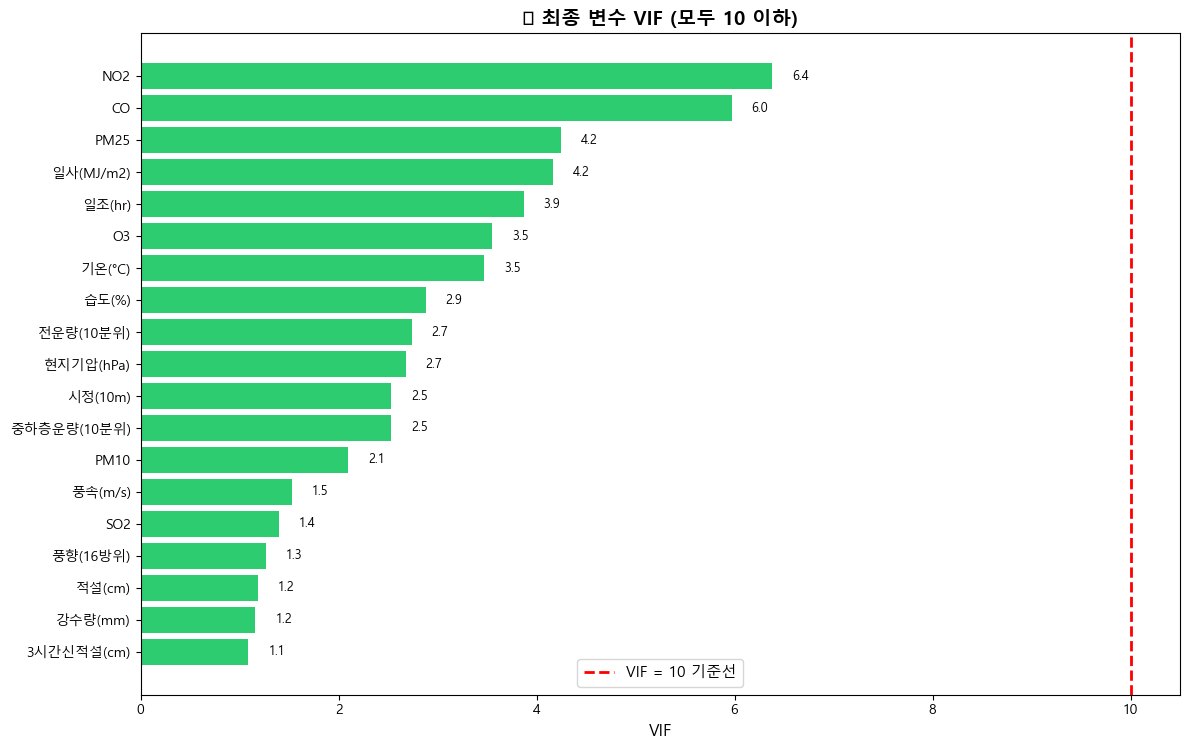

C:\Users\5174k\AppData\Local\Temp\ipykernel_42336\336102163.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
c:\Users\5174k\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


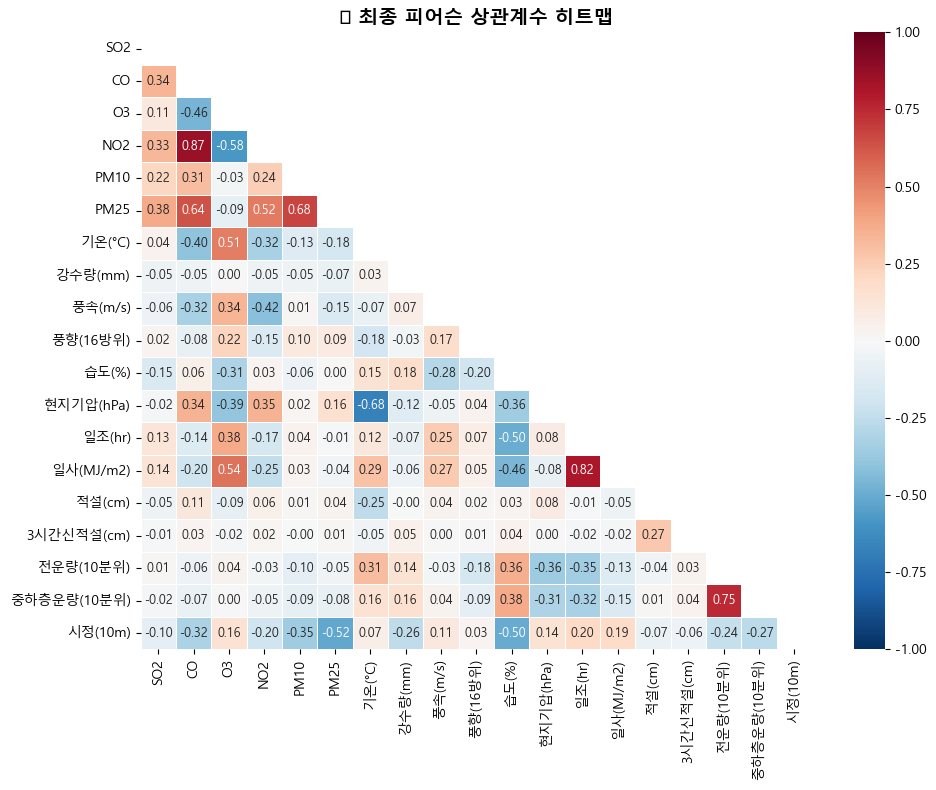


📋 제거된 변수 전체 목록

[상관계수 |r| > 0.9 제거] (7개):
   ❌ 해면기압(hPa)
   ❌ 10cm 지중온도(°C)
   ❌ 20cm 지중온도(°C)
   ❌ 5cm 지중온도(°C)
   ❌ 이슬점온도(°C)
   ❌ 지면온도(°C)
   ❌ 30cm 지중온도(°C)

[VIF > 10 반복 제거] (1개):
   ❌ 증기압(hPa) (VIF=10.4)

총 제거: 8개  /  남은 변수: 19개
남은 변수 목록: ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '현지기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)']


In [7]:
# ============================================================
# 📊 VIF > 10 반복 제거 + 피어슨 |r| > 0.9 제거 코드
# ============================================================
# 노트북 맨 아래 셀에 붙여넣기 (독립 실행 가능)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ── 데이터 로드 ──
train_x = pd.read_csv('train_x.csv', index_col=0)

# ── 파생변수 제외 ──
drop_from_analysis = ['hour', 'PM10_lag24', 'PM10_lag1', 'PM10_lag']
analysis_cols = [c for c in train_x.select_dtypes(include=[np.number]).columns
                 if c not in drop_from_analysis]
df = train_x[analysis_cols].dropna()
print(f'✅ 시작 변수 ({len(analysis_cols)}개): {analysis_cols}\n')

# ── VIF 계산 함수 ──
def calc_vif(df):
    X = df.values.astype(float)
    vifs = {}
    for i, col in enumerate(df.columns):
        y = X[:, i]
        X_rest = np.delete(X, i, axis=1)
        X_rest = np.hstack([np.ones((X_rest.shape[0], 1)), X_rest])
        beta = np.linalg.lstsq(X_rest, y, rcond=None)[0]
        y_pred = X_rest @ beta
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        r_sq = 1 - ss_res / ss_tot if ss_tot != 0 else 0
        vifs[col] = round(1 / (1 - r_sq) if r_sq < 1 else float('inf'), 2)
    return vifs


# ==========================================
# [1] 피어슨 |r| > 0.9 쌍에서 VIF 높은 쪽 제거
# ==========================================
print('=' * 60)
print('📊 [1단계] 피어슨 |r| > 0.9 → VIF 높은 쪽 제거')
print('=' * 60)

corr = df.corr()
corr_removed = []

while True:
    # 상삼각에서 |r| > 0.9인 쌍 찾기
    pairs = []
    for i in range(len(corr.columns)):
        for j in range(i+1, len(corr.columns)):
            if abs(corr.iloc[i, j]) > 0.9:
                pairs.append((corr.columns[i], corr.columns[j], abs(corr.iloc[i, j])))
    
    if not pairs:
        break
    
    # 가장 높은 상관 쌍
    pairs.sort(key=lambda x: x[2], reverse=True)
    c1, c2, r_val = pairs[0]
    
    # 둘 중 VIF 높은 쪽 제거
    vifs = calc_vif(df[[c1, c2]])  # 간단히 두 변수만으로는 부정확 → 전체로 계산
    vifs_full = calc_vif(df)
    v1, v2 = vifs_full[c1], vifs_full[c2]
    
    drop_col = c1 if v1 >= v2 else c2
    keep_col = c2 if drop_col == c1 else c1
    
    print(f'\n   {c1} ↔ {c2}  |r| = {r_val:.4f}')
    print(f'   → {c1} VIF={v1}  /  {c2} VIF={v2}')
    print(f'   → {drop_col} 제거 (VIF 더 높음), {keep_col} 유지 ✅')
    
    corr_removed.append(drop_col)
    df = df.drop(columns=[drop_col])
    corr = df.corr()

print(f'\n🔴 상관계수로 제거된 변수 ({len(corr_removed)}개): {corr_removed}')


# ==========================================
# [2] VIF > 10 반복 제거
# ==========================================
print('\n' + '=' * 60)
print('📊 [2단계] VIF > 10 반복 제거 (가장 높은 것부터)')
print('=' * 60)

vif_removed = []
step = 0

while True:
    vifs = calc_vif(df)
    max_col = max(vifs, key=vifs.get)
    max_vif = vifs[max_col]
    
    if max_vif <= 10:
        print(f'\n   ✅ 모든 변수 VIF ≤ 10 달성! (반복 {step}회)')
        break
    
    step += 1
    print(f'   [{step}회] {max_col} 제거 (VIF = {max_vif:,.1f})')
    vif_removed.append((max_col, max_vif))
    df = df.drop(columns=[max_col])

print(f'\n🔴 VIF로 제거된 변수 ({len(vif_removed)}개):')
for col, v in vif_removed:
    print(f'   - {col} (VIF = {v:,.1f})')


# ==========================================
# [3] 최종 결과
# ==========================================
print('\n' + '=' * 60)
print('📋 [최종 결과]')
print('=' * 60)

all_removed = corr_removed + [c for c, v in vif_removed]
final_cols = df.columns.tolist()

# 최종 VIF
final_vifs = calc_vif(df)
vif_final = pd.DataFrame({
    '변수명': list(final_vifs.keys()),
    'VIF': list(final_vifs.values())
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print(f'\n✅ 남은 변수 ({len(final_cols)}개):')
print(vif_final.to_string(index=False))

# 최종 VIF 그래프
fig, ax = plt.subplots(figsize=(12, max(5, len(final_cols)*0.4)))
colors = ['#e74c3c' if v > 10 else '#2ecc71' for v in vif_final['VIF']]
bars = ax.barh(vif_final['변수명'], vif_final['VIF'], color=colors)
ax.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF = 10 기준선')
ax.set_xlabel('VIF', fontsize=12)
ax.set_title('✅ 최종 변수 VIF (모두 10 이하)', fontsize=14, fontweight='bold')
for bar, v in zip(bars, vif_final['VIF']):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
            f'{v:.1f}', va='center', fontsize=9)
ax.legend(fontsize=11)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# 최종 상관계수 히트맵
fig, ax = plt.subplots(figsize=(10, 8))
final_corr = df.corr()
mask = np.triu(np.ones_like(final_corr, dtype=bool))
sns.heatmap(final_corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size': 9}, ax=ax)
ax.set_title('✅ 최종 피어슨 상관계수 히트맵', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 전체 요약
print('\n' + '=' * 60)
print('📋 제거된 변수 전체 목록')
print('=' * 60)
print(f'\n[상관계수 |r| > 0.9 제거] ({len(corr_removed)}개):')
for c in corr_removed:
    print(f'   ❌ {c}')
print(f'\n[VIF > 10 반복 제거] ({len(vif_removed)}개):')
for c, v in vif_removed:
    print(f'   ❌ {c} (VIF={v:,.1f})')
print(f'\n총 제거: {len(all_removed)}개  /  남은 변수: {len(final_cols)}개')
print(f'남은 변수 목록: {final_cols}')



📊 [선형 회귀] 남은 변수로 PM10 예측

학습에 사용할 변수 (21개): ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '현지기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)', 'PM10_lag24', 'PM10_lag1']

📈 성능 결과:
   Train R² = 0.9652
   Test  R² = 0.9339
   Test MAE = 3.90
   Test RMSE = 6.09

📊 회귀 계수 (영향력 순):
         변수        회귀계수
        SO2 -110.884075
        NO2   46.257587
         O3   24.575083
         CO    3.406464
 3시간신적설(cm)    1.262172
       PM10    0.989399
  일사(MJ/m2)    0.611411
     일조(hr)   -0.477709
    강수량(mm)   -0.210827
중하층운량(10분위)    0.067601
     적설(cm)   -0.064664
  전운량(10분위)   -0.058188
       PM25   -0.042732
  현지기압(hPa)   -0.039777
     기온(°C)   -0.032419
      습도(%)    0.013505
 PM10_lag24   -0.009699
  PM10_lag1   -0.009699
    풍속(m/s)    0.003830
   풍향(16방위)    0.002538
    시정(10m)    0.000035


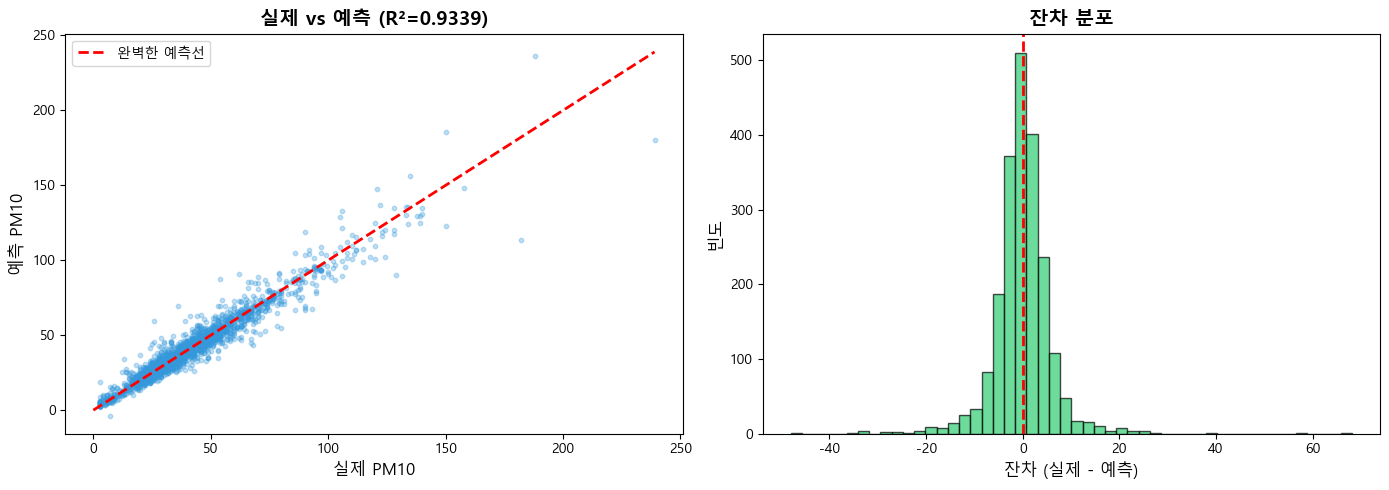


✅ 선형 회귀 분석 완료!


In [8]:

# ==========================================
# [5] 선형 회귀 (남은 변수로)
# ==========================================
print('\n' + '=' * 60)
print('📊 [선형 회귀] 남은 변수로 PM10 예측')
print('=' * 60)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 데이터 로드
train_y = pd.read_csv('train_y.csv', index_col=0)
test_x = pd.read_csv('test_x.csv', index_col=0)
test_y = pd.read_csv('test_y.csv', index_col=0)

# 파생변수 중 남아있는 것도 포함 (PM10_lag24, PM10_lag1 등)
lag_cols = [c for c in ['PM10_lag24', 'PM10_lag1'] if c in train_x.columns and c in test_x.columns]
use_cols = final_cols + lag_cols
use_cols = [c for c in use_cols if c in train_x.columns and c in test_x.columns]

print(f'\n학습에 사용할 변수 ({len(use_cols)}개): {use_cols}')

X_train = train_x[use_cols].dropna()
y_train = train_y.loc[X_train.index]
X_test = test_x[use_cols].dropna()
y_test = test_y.loc[X_test.index]

# 선형 회귀 학습
model = LinearRegression()
model.fit(X_train, y_train)

# 예측
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

# 평가
train_r2 = r2_score(y_train, pred_train)
test_r2 = r2_score(y_test, pred_test)
test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print(f'\n📈 성능 결과:')
print(f'   Train R² = {train_r2:.4f}')
print(f'   Test  R² = {test_r2:.4f}')
print(f'   Test MAE = {test_mae:.2f}')
print(f'   Test RMSE = {test_rmse:.2f}')

# 회귀 계수
coef_df = pd.DataFrame({
    '변수': use_cols,
    '회귀계수': model.coef_.flatten()
}).sort_values('회귀계수', ascending=False, key=abs).reset_index(drop=True)
print(f'\n📊 회귀 계수 (영향력 순):')
print(coef_df.to_string(index=False))

# 실제 vs 예측 산점도
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, pred_test, alpha=0.3, s=10, color='#3498db')
axes[0].plot([0, y_test.max().values[0]], [0, y_test.max().values[0]], 
             'r--', linewidth=2, label='완벽한 예측선')
axes[0].set_xlabel('실제 PM10', fontsize=12)
axes[0].set_ylabel('예측 PM10', fontsize=12)
axes[0].set_title(f'실제 vs 예측 (R²={test_r2:.4f})', fontsize=14, fontweight='bold')
axes[0].legend()

# 잔차 분포
residuals = y_test.values.flatten() - pred_test.flatten()
axes[1].hist(residuals, bins=50, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('잔차 (실제 - 예측)', fontsize=12)
axes[1].set_ylabel('빈도', fontsize=12)
axes[1].set_title('잔차 분포', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print('\n✅ 선형 회귀 분석 완료!')


✅ 학습 변수 (21개): ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '현지기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)', 'PM10_lag24', 'PM10_lag1']

📈 [전체 2022] 성능:
   Train R² = 0.9652
   Test  R² = 0.9339
   Test MAE = 3.90
   Test RMSE = 6.09

📊 회귀 계수 (영향력 순):
         변수        회귀계수
        SO2 -110.884075
        NO2   46.257587
         O3   24.575083
         CO    3.406464
 3시간신적설(cm)    1.262172
       PM10    0.989399
  일사(MJ/m2)    0.611411
     일조(hr)   -0.477709
    강수량(mm)   -0.210827
중하층운량(10분위)    0.067601
     적설(cm)   -0.064664
  전운량(10분위)   -0.058188
       PM25   -0.042732
  현지기압(hPa)   -0.039777
     기온(°C)   -0.032419
      습도(%)    0.013505
 PM10_lag24   -0.009699
  PM10_lag1   -0.009699
    풍속(m/s)    0.003830
   풍향(16방위)    0.002538
    시정(10m)    0.000035

--------------------------------------------------
🔥 울진삼척 산불(2022-03-04 ~ 03-06) 제외 재평가
------------------------------

C:\Users\5174k\AppData\Local\Temp\ipykernel_42336\409118239.py:96: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
c:\Users\5174k\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


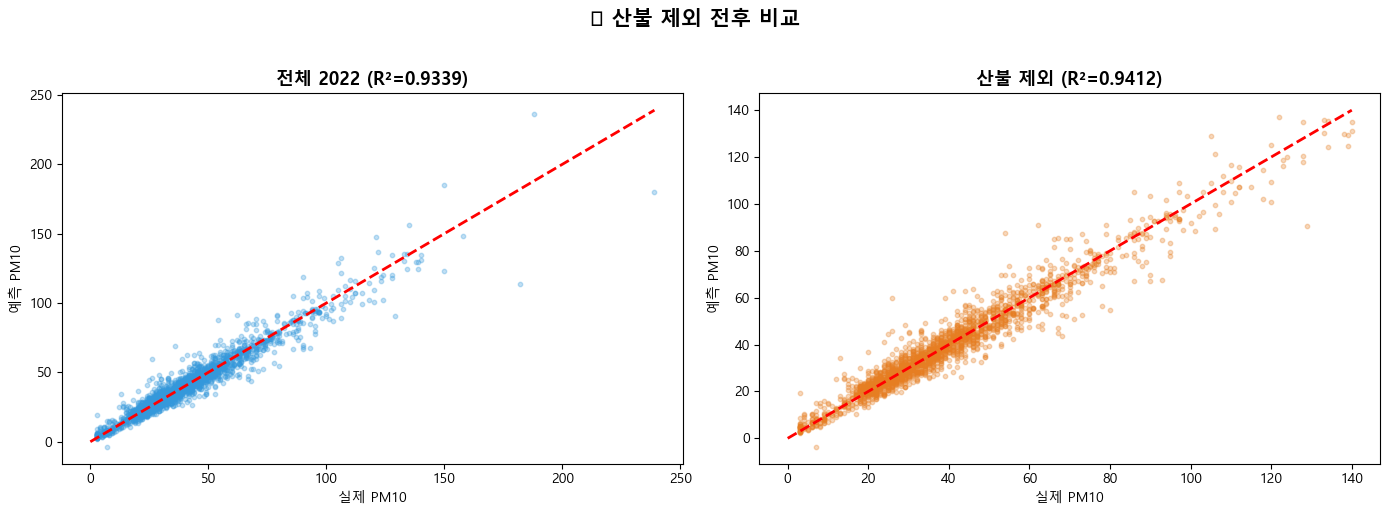


✅ 완료!


In [11]:
# ============================================================
# 📊 선형 회귀: VIF/상관계수 정리 후 남은 변수로 PM10 예측
# ============================================================
# 새로운 셀에 붙여넣기 (vif_correlation_check 실행 후 사용)
# final_cols 변수가 필요합니다
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 데이터 로드
train_x = pd.read_csv('train_x.csv', index_col=0)
train_y = pd.read_csv('train_y.csv', index_col=0)
test_x = pd.read_csv('test_x.csv', index_col=0)
test_y = pd.read_csv('test_y.csv', index_col=0)

# VIF/상관계수 분석에서 살아남은 변수 + lag 변수
lag_cols = [c for c in ['PM10_lag24', 'PM10_lag1'] if c in train_x.columns and c in test_x.columns]
use_cols = final_cols + lag_cols
use_cols = [c for c in use_cols if c in train_x.columns and c in test_x.columns]
print(f'✅ 학습 변수 ({len(use_cols)}개): {use_cols}\n')

# 학습/테스트 데이터 준비
X_train = train_x[use_cols].dropna()
y_train = train_y.loc[X_train.index]
X_test = test_x[use_cols].dropna()
y_test = test_y.loc[X_test.index]

# ── 선형 회귀 학습 (2021) & 평가 (2022) ──
model = LinearRegression()
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

train_r2 = r2_score(y_train, pred_train)
test_r2 = r2_score(y_test, pred_test)
test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print(f'📈 [전체 2022] 성능:')
print(f'   Train R² = {train_r2:.4f}')
print(f'   Test  R² = {test_r2:.4f}')
print(f'   Test MAE = {test_mae:.2f}')
print(f'   Test RMSE = {test_rmse:.2f}')

# 회귀 계수
coef_df = pd.DataFrame({
    '변수': use_cols,
    '회귀계수': model.coef_.flatten()
}).sort_values('회귀계수', ascending=False, key=abs).reset_index(drop=True)
print(f'\n📊 회귀 계수 (영향력 순):')
print(coef_df.to_string(index=False))

# ── 산불 기간(03/04~03/06) 제외 재평가 ──
print('\n' + '-' * 50)
print('🔥 울진삼척 산불(2022-03-04 ~ 03-06) 제외 재평가')
print('-' * 50)

test_idx = pd.to_datetime(X_test.index)
fire_mask = (test_idx >= '2022-03-04') & (test_idx < '2022-03-07')

X_test_clean = X_test[~fire_mask]
y_test_clean = y_test.loc[X_test_clean.index]
pred_clean = model.predict(X_test_clean)

clean_r2 = r2_score(y_test_clean, pred_clean)
clean_mae = mean_absolute_error(y_test_clean, pred_clean)
clean_rmse = np.sqrt(mean_squared_error(y_test_clean, pred_clean))

print(f'\n   제거 데이터: {fire_mask.sum()}개  /  남은 데이터: {len(X_test_clean)}개')
print(f'\n📈 성능 비교:')
print(f'   {"":15s} {"전체 2022":>10s}  {"산불 제외":>10s}')
print(f'   {"R²":15s} {test_r2:>10.4f}  {clean_r2:>10.4f}')
print(f'   {"MAE":15s} {test_mae:>10.2f}  {clean_mae:>10.2f}')
print(f'   {"RMSE":15s} {test_rmse:>10.2f}  {clean_rmse:>10.2f}')

# ── 비교 시각화 ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, pred_test, alpha=0.3, s=10, color='#3498db')
mx = max(y_test.max().values[0], pred_test.max())
axes[0].plot([0, mx], [0, mx], 'r--', linewidth=2)
axes[0].set_xlabel('실제 PM10')
axes[0].set_ylabel('예측 PM10')
axes[0].set_title(f'전체 2022 (R²={test_r2:.4f})', fontsize=13, fontweight='bold')

axes[1].scatter(y_test_clean, pred_clean, alpha=0.3, s=10, color='#e67e22')
mx2 = max(y_test_clean.max().values[0], pred_clean.max())
axes[1].plot([0, mx2], [0, mx2], 'r--', linewidth=2)
axes[1].set_xlabel('실제 PM10')
axes[1].set_ylabel('예측 PM10')
axes[1].set_title(f'산불 제외 (R²={clean_r2:.4f})', fontsize=13, fontweight='bold')

plt.suptitle('🔥 산불 제외 전후 비교', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n✅ 완료!')


✅ PM 제거 후 학습 변수 (17개): ['SO2', 'CO', 'O3', 'NO2', '기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '현지기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)']

📈 [PM 제거] 성능:
   Train R² = 0.2794
   Test  R² = 0.3690
   Test MAE = 13.87
   Test RMSE = 18.82

📊 회귀 계수 (영향력 순):
         변수        회귀계수
        SO2 2889.443685
        NO2  335.254375
         CO   31.154643
         O3   22.716630
     일조(hr)   -8.385025
    강수량(mm)   -4.602029
     적설(cm)   -3.938016
  일사(MJ/m2)    2.987323
    풍속(m/s)    2.581954
  전운량(10분위)   -1.181217
  현지기압(hPa)   -1.039286
중하층운량(10분위)   -0.835510
      습도(%)   -0.625792
 3시간신적설(cm)    0.327062
     기온(°C)   -0.250443
    시정(10m)   -0.040896
   풍향(16방위)    0.022227

--------------------------------------------------
🔥 산불(2022-03-04 ~ 03-06) 제외 재평가
--------------------------------------------------

📈 성능 비교 (PM 제거 모델):
                      전체 2022       산불 제외
   R²                  0.3690      0.3637
   MAE    

C:\Users\5174k\AppData\Local\Temp\ipykernel_42336\4243831722.py:94: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
c:\Users\5174k\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


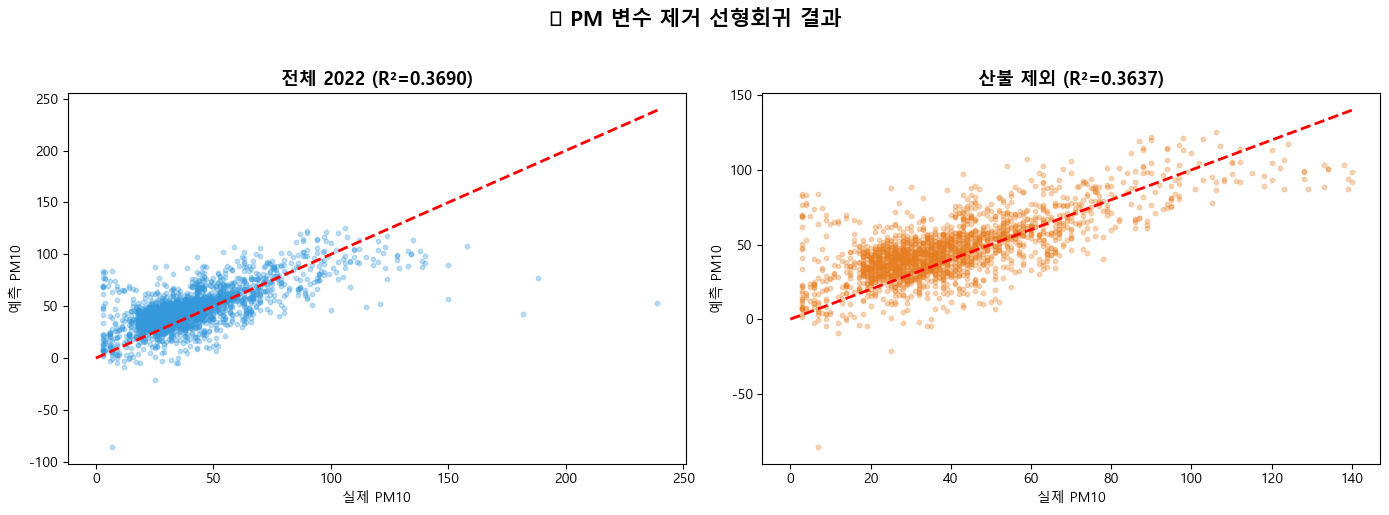


✅ PM 제거 선형 회귀 완료!


In [12]:
# ============================================================
# 📊 선형 회귀: PM 변수(PM10, PM25) 제거 후 예측
# ============================================================
# 새로운 셀에 붙여넣기 (vif_correlation_check 실행 후 사용)
# final_cols 변수가 필요합니다
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 데이터 로드
train_x = pd.read_csv('train_x.csv', index_col=0)
train_y = pd.read_csv('train_y.csv', index_col=0)
test_x = pd.read_csv('test_x.csv', index_col=0)
test_y = pd.read_csv('test_y.csv', index_col=0)

# PM 변수 + lag 변수 전부 제거
pm_cols = ['PM10', 'PM25', 'PM10_lag24', 'PM10_lag1']
use_cols_no_pm = [c for c in final_cols if c not in pm_cols]
print(f'✅ PM 제거 후 학습 변수 ({len(use_cols_no_pm)}개): {use_cols_no_pm}\n')

# 데이터 준비
X_train = train_x[use_cols_no_pm].dropna()
y_train = train_y.loc[X_train.index]
X_test = test_x[use_cols_no_pm].dropna()
y_test = test_y.loc[X_test.index]

# 선형 회귀 학습 & 예측
model_no_pm = LinearRegression()
model_no_pm.fit(X_train, y_train)

pred_train = model_no_pm.predict(X_train)
pred_test = model_no_pm.predict(X_test)

train_r2 = r2_score(y_train, pred_train)
test_r2 = r2_score(y_test, pred_test)
test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print(f'📈 [PM 제거] 성능:')
print(f'   Train R² = {train_r2:.4f}')
print(f'   Test  R² = {test_r2:.4f}')
print(f'   Test MAE = {test_mae:.2f}')
print(f'   Test RMSE = {test_rmse:.2f}')

# 회귀 계수
coef_df = pd.DataFrame({
    '변수': use_cols_no_pm,
    '회귀계수': model_no_pm.coef_.flatten()
}).sort_values('회귀계수', ascending=False, key=abs).reset_index(drop=True)
print(f'\n📊 회귀 계수 (영향력 순):')
print(coef_df.to_string(index=False))

# ── 산불 기간 제외 재평가 ──
print('\n' + '-' * 50)
print('🔥 산불(2022-03-04 ~ 03-06) 제외 재평가')
print('-' * 50)

test_idx = pd.to_datetime(X_test.index)
fire_mask = (test_idx >= '2022-03-04') & (test_idx < '2022-03-07')

X_test_clean = X_test[~fire_mask]
y_test_clean = y_test.loc[X_test_clean.index]
pred_clean = model_no_pm.predict(X_test_clean)

clean_r2 = r2_score(y_test_clean, pred_clean)
clean_mae = mean_absolute_error(y_test_clean, pred_clean)
clean_rmse = np.sqrt(mean_squared_error(y_test_clean, pred_clean))

print(f'\n📈 성능 비교 (PM 제거 모델):')
print(f'   {"":15s} {"전체 2022":>10s}  {"산불 제외":>10s}')
print(f'   {"R²":15s} {test_r2:>10.4f}  {clean_r2:>10.4f}')
print(f'   {"MAE":15s} {test_mae:>10.2f}  {clean_mae:>10.2f}')
print(f'   {"RMSE":15s} {test_rmse:>10.2f}  {clean_rmse:>10.2f}')

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, pred_test, alpha=0.3, s=10, color='#3498db')
mx = max(y_test.max().values[0], pred_test.max())
axes[0].plot([0, mx], [0, mx], 'r--', linewidth=2)
axes[0].set_xlabel('실제 PM10')
axes[0].set_ylabel('예측 PM10')
axes[0].set_title(f'전체 2022 (R²={test_r2:.4f})', fontsize=13, fontweight='bold')

axes[1].scatter(y_test_clean, pred_clean, alpha=0.3, s=10, color='#e67e22')
mx2 = max(y_test_clean.max().values[0], pred_clean.max())
axes[1].plot([0, mx2], [0, mx2], 'r--', linewidth=2)
axes[1].set_xlabel('실제 PM10')
axes[1].set_ylabel('예측 PM10')
axes[1].set_title(f'산불 제외 (R²={clean_r2:.4f})', fontsize=13, fontweight='bold')

plt.suptitle('📊 PM 변수 제거 선형회귀 결과', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n✅ PM 제거 선형 회귀 완료!')


In [ ]:
Isabelle Guyon and André Elisseeff. 2003. 
An introduction to variable and feature selection. 
